[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L1/BA_L1_value_activity/BA_L1_value_activity.ipynb)

# BA_L1_value_activity: Market Value and Network Activity

*Quantlet of Lecture 1, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Monthly means of Bitcoin market value against transactions per day on log-log scales, November 2014 to October 2025, coloured by year, with the correlation of the logs and the slope (elasticity) of the log-log line.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

In [4]:
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 10, 'axes.titlesize': 10, 'lines.linewidth': 1.5})   # as in the slide charts


def load_onchain(name):
    # daily on-chain series, one column per coin, as numbers (missing values are NaN)
    return onchain(name).apply(pd.to_numeric, errors='coerce')


def slide_legend(fig, bottom, ncol=3):
    # one legend for the whole figure, under the plots, as in the slides
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))

## Data and method

Monthly means of Bitcoin's market value $M$ (USD) and transactions per day $n$, with the 11 days of recording error
(27 August to 6 September 2023) removed. The slope $b$ of the least-squares line

$$\log_{10} M = a + b \log_{10} n$$

is an **elasticity**: 1% more transactions goes with about $b$% more market value. Network-value theories such as
Metcalfe's law predict $b = 2$ (tested formally in Lecture 2).

**How to read the chart.** Each point is a month; its colour is the year. A tight upward line would mean that value
follows activity; a wide cloud means that value also moves for other reasons.

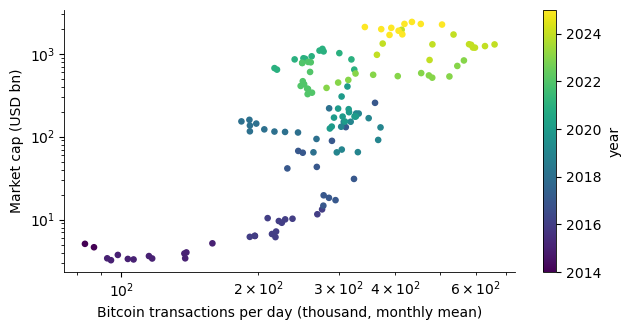

In [5]:
tx, mc = load_onchain('transaction'), load_onchain('Mktcap')
mc.loc['2023-08-27':'2023-09-06', 'BTC'] = np.nan          # recording error
m = pd.DataFrame({'tx': tx['BTC'], 'mc': mc['BTC']}).dropna().resample('ME').mean()
x, y = np.log10(m['tx']), np.log10(m['mc'])
b, a = np.polyfit(x, y, 1)

fig, axx = plt.subplots(figsize=(6.5, 3.4))
sc = axx.scatter(m['tx'] / 1e3, m['mc'] / 1e9, c=m.index.year, cmap='viridis', s=14)
axx.set_xscale('log'); axx.set_yscale('log')
axx.set_xlabel('Bitcoin transactions per day (thousand, monthly mean)'); axx.set_ylabel('Market cap (USD bn)')
fig.colorbar(sc, ax=axx).set_label('year')
fig.tight_layout()
save_fig(fig, 'ba_l1_value_activity')

In [6]:
print(f'Months: {len(m)} ({m.index[0]:%b %Y} to {m.index[-1]:%b %Y})')
print(f'Correlation of log market value and log transactions: {np.corrcoef(x, y)[0, 1]:.2f}')
print(f'Slope of the log-log line (elasticity): {b:.2f}')

Months: 132 (Nov 2014 to Oct 2025)
Correlation of log market value and log transactions: 0.76
Slope of the log-log line (elasticity): 3.59
